# 03 — Transformations, Stationarity and BVAR-Ready Data

## What this notebook does
1. **Load the clean quarterly panel** — import the cleaned quarterly data constructed in notebook 02 and retain the variables used in the baseline BVAR
2. **Assess stationarity and structural breaks** — examine the time-series properties that motivate the final empirical specification, with special treatment of bilateral GPR indices
3. **Apply the final transformations** — construct `log(1 + GPR)`, quarterly log-differences for Brent, Gas, HICP and IPI, and retain CLIFS in levels
4. **Inspect the transformed series** — visualise the final BVAR variables and relate their main movements to major geopolitical and macro-financial episodes
5. **Build the BVAR-ready dataset** — validate and export the final transformed panel used by the subsequent BVAR notebooks

## Final empirical specification
For each recipient economy and GPR origin, the baseline system is:

`[GPR_origin, Brent, Gas_TTF, HICP, IPI, CLIFS]`

with the following transformations:

- GPR: `log(1 + GPR)`
- Brent: `Δlog(Brent)`
- Gas: `Δlog(Gas)`
- HICP: `Δlog(HICP)`
- IPI: `Δlog(IPI)`
- CLIFS: levels

The clean quarterly panel begins in **1997Q1**. Because log-differences require one lagged observation, the final transformed sample begins in **1997Q2** and ends in **2025Q4**.

## A. Setup and clean quarterly panel

Notebook 02 has already resolved the data-construction choices. From this point onwards, the analysis focuses only on the variables entering the baseline BVAR.

GDP is therefore no longer part of the working dataset: its role was to justify and test the choice of IPI as the baseline activity indicator.

In [1]:
!pip -q install ruptures

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 42.8 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss
import ruptures as rpt

warnings.filterwarnings("ignore", category=UserWarning)

# Support both Google Colab and local execution
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/TFM_GitHub")
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "notebooks").exists():
    raise FileNotFoundError(
        f"Could not find the project under: {PROJECT_ROOT}"
    )

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures" / "03_transformations"
TABLE_DIR = OUTPUT_DIR / "tables" / "03_transformations"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COUNTRIES = ["Germany", "France", "Italy", "Spain"]
GPR_ORIGINS = ["Russia", "China", "Middle East", "Western Bloc"]

SAMPLE_START = "1997Q1"
ESTIMATION_START = "1997Q2"
SAMPLE_END = "2025Q4"

print(f"Project root: {PROJECT_ROOT}")

Mounted at /content/drive
Project root: /content/drive/MyDrive/TFM_GitHub


In [3]:
# Locate the clean quarterly panel exported by notebook 02.
# The first existing candidate is used so that the notebook remains compatible
# if the descriptive filename is slightly adjusted while finalising notebook 02.

panel_candidates = [
    PROCESSED_DIR / "02_clean_quarterly_panel.xlsx",
    PROCESSED_DIR / "clean_quarterly_panel.xlsx",
    PROCESSED_DIR / "03_clean_quarterly_panel.xlsx",
]

CLEAN_PANEL_PATH = next((p for p in panel_candidates if p.exists()), None)

if CLEAN_PANEL_PATH is None:
    raise FileNotFoundError(
        "Clean quarterly panel not found. Run notebook 02 first and check its export filename."
    )

panel = pd.read_excel(CLEAN_PANEL_PATH)
print(f"Loaded: {CLEAN_PANEL_PATH.name}")
print(f"Shape: {panel.shape}")
display(panel.head())

Loaded: 03_clean_quarterly_panel.xlsx
Shape: (464, 12)


,quarter,country,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
0,1997Q1,Germany,9.474874,0.000000,38.046743,24.595479,21.170000,2.870000,76.598778,76.066667,77.772,0.085600
1,1997Q1,France,38.417008,55.899691,24.376497,48.921747,21.170000,2.870000,75.680072,95.500000,73.303,0.114067
2,1997Q1,Italy,46.894347,80.050832,33.450371,52.583083,21.170000,2.870000,69.388538,111.933333,91.891,0.082000
3,1997Q1,Spain,47.502121,18.240746,51.703130,58.781181,21.170000,2.870000,65.791649,103.333333,69.662,0.089667
4,1997Q2,Germany,22.084295,33.970353,45.825273,44.950218,18.053333,2.756667,76.703236,76.766667,78.637,0.096167


In [4]:
# Standardise the quarter column without changing the underlying data.
quarter_candidates = ["quarter", "Quarter", "date", "Date"]
quarter_col = next((c for c in quarter_candidates if c in panel.columns), None)

if quarter_col is None:
    raise KeyError("No quarter/date column found in the clean panel.")

panel = panel.rename(columns={quarter_col: "quarter"})
panel["quarter"] = pd.PeriodIndex(panel["quarter"].astype(str), freq="Q")

# Work only with the final TFM window.
panel = panel[
    (panel["quarter"] >= pd.Period(SAMPLE_START, freq="Q")) &
    (panel["quarter"] <= pd.Period(SAMPLE_END, freq="Q"))
].copy()

print(panel["quarter"].min(), "to", panel["quarter"].max())
print("Rows:", len(panel))

1997Q1 to 2025Q4
Rows: 464


## B. Why are the variables transformed this way?

The transformations are not applied mechanically. They reflect both the statistical properties of the series and the economic interpretation required by the BVAR.

For **Brent, Gas, HICP and IPI**, unit-root evidence motivates the use of quarterly log-differences. **CLIFS** is retained in levels because the stationarity evidence supports that treatment and its level has a direct interpretation as the degree of systemic financial stress.

The bilateral **GPR indices require separate treatment**. Standard unit-root tests can be misleading when a series contains structural breaks. The GPR indices display abrupt changes around major geopolitical episodes, so their persistence is examined allowing for breaks rather than treating a failure to reject a unit root in the full sample as definitive evidence of an I(1) process.

### B1. Brent, Gas, HICP, IPI and CLIFS

ADF and KPSS provide complementary evidence:

- **ADF null hypothesis:** the series has a unit root.
- **KPSS null hypothesis:** the series is stationary.

The tests are first applied to the cleaned level series. They document the persistence that motivates the final transformation choices.

In [5]:
def stationarity_tests(series, name, country=None):
    x = pd.Series(series).dropna().astype(float)

    adf_stat, adf_p, _, _, _, _ = adfuller(x, autolag="BIC")
    kpss_stat, kpss_p, _, _ = kpss(x, regression="c", nlags="auto")

    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = "stationary"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = "non-stationary"
    else:
        verdict = "conflicting"

    return {
        "country": country,
        "variable": name,
        "n": len(x),
        "adf_stat": adf_stat,
        "adf_pvalue": adf_p,
        "kpss_stat": kpss_stat,
        "kpss_pvalue": kpss_p,
        "verdict": verdict,
    }

In [6]:
# Resolve the final column names used by notebook 02.
def find_column(df, candidates):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    raise KeyError(f"None of these columns were found: {candidates}")

COUNTRY_COL = "country"

BRENT_COL = "brent_usd"
GAS_COL = "gas_usd"
HICP_COL = "hicp"
IPI_COL = "ipi"
CLIFS_COL = "clifs"

GPR_COLS = {
    "Russia": "GPR_Russia",
    "China": "GPR_China",
    "Middle East": "GPR_MENA",
    "Western Bloc": "GPR_Western",
}

resolved_columns = {
    "country": COUNTRY_COL,
    "Brent": BRENT_COL,
    "Gas": GAS_COL,
    "HICP": HICP_COL,
    "IPI": IPI_COL,
    "CLIFS": CLIFS_COL,
}

display(pd.Series(resolved_columns, name="panel_column").to_frame())

,panel_column
country,country
Brent,brent_usd
Gas,gas_usd
HICP,hicp
IPI,ipi
CLIFS,clifs


In [7]:
stationarity_rows = []

# Brent and Gas are common across countries, so testing one non-duplicated
# quarterly series is sufficient.
common = (
    panel[["quarter", BRENT_COL, GAS_COL]]
    .drop_duplicates("quarter")
    .sort_values("quarter")
)

for variable, col in [("Brent", BRENT_COL), ("Gas", GAS_COL)]:
    stationarity_rows.append(stationarity_tests(common[col], variable))

# Country-specific macro-financial variables.
for country in TARGET_COUNTRIES:
    sub = panel[panel[COUNTRY_COL] == country].sort_values("quarter")

    for variable, col in [
        ("HICP", HICP_COL),
        ("IPI", IPI_COL),
        ("CLIFS", CLIFS_COL),
    ]:
        stationarity_rows.append(
            stationarity_tests(sub[col], variable, country=country)
        )

level_stationarity = pd.DataFrame(stationarity_rows)
display(level_stationarity.round(4))
level_stationarity.to_csv(
    TABLE_DIR / "01_level_stationarity_tests.csv", index=False
)

/tmp/ipykernel_890/4091271702.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, _, _ = adfuller(x, autolag="BIC")
/tmp/ipykernel_890/4091271702.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_stat, kpss_p, _, _ = kpss(x, regression="c", nlags="auto")
/tmp/ipykernel_890/4091271702.py:4: FutureWarning:

,country,variable,n,adf_stat,adf_pvalue,kpss_stat,kpss_pvalue,verdict
0,None,Brent,116,-2.5454,0.1048,0.7743,0.0100,non-stationary
1,None,Gas,116,-3.2100,0.0194,0.6557,0.0176,conflicting
2,Germany,HICP,116,2.1020,0.9988,1.6242,0.0100,non-stationary
3,Germany,IPI,116,-2.3519,0.1558,1.0611,0.0100,non-stationary
4,Germany,CLIFS,116,-3.8531,0.0024,0.2004,0.1000,stationary
5,France,HICP,116,0.5625,0.9867,1.6749,0.0100,non-stationary
6,France,IPI,116,-3.1160,0.0254,0.6807,0.0153,conflicting
7,France,CLIFS,116,-4.1358,0.0008,0.0580,0.1000,stationary
8,Italy,HICP,116,0.3319,0.9788,1.6774,0.0100,non-stationary
9,Italy,IPI,116,-1.4537,0.5563,1.3721,0.0100,non-stationary


In [8]:
stationarity_summary = (
    level_stationarity
    .groupby("variable")["verdict"]
    .value_counts()
    .unstack(fill_value=0)
)

display(stationarity_summary)

verdict,conflicting,non-stationary,stationary
variable,,,
Brent,0,1,0
CLIFS,0,0,4
Gas,1,0,0
HICP,0,4,0
IPI,1,3,0


### B2. Bilateral GPR: structural breaks and piecewise stationarity

The GPR indices are not treated as ordinary persistent macroeconomic series. Major geopolitical events can shift their mean abruptly, reducing the power of conventional full-sample unit-root tests.

The final TFM therefore examines the transformed bilateral indices using the **PELT structural-break algorithm** and then applies **ADF tests within the resulting regimes**.

This evidence should be interpreted cautiously: it does **not** establish uniform piecewise stationarity for all 16 country-origin series. Instead, it shows that a substantial part of the apparent persistence is associated with discrete shifts and exceptional geopolitical episodes rather than a smooth stochastic trend.

This supports retaining GPR in levels while recognising the uncertainty surrounding its time-series properties.

In [9]:
# Identify the four bilateral GPR columns produced by notebook 02.
GPR_COLUMN_CANDIDATES = {
    "Russia": ["GPR_Russia", "Russia", "gpr_russia"],
    "China": ["GPR_China", "China", "gpr_china"],
    "Middle East": [
        "GPR_Middle_East", "GPR_MENA", "Middle East", "MENA", "gpr_mena"
    ],
    "Western Bloc": [
        "GPR_Western_Bloc", "GPR_Western", "Western Bloc",
        "Western", "gpr_western"
    ],
}

GPR_COLS = {
    origin: find_column(panel, candidates)
    for origin, candidates in GPR_COLUMN_CANDIDATES.items()
}

display(pd.Series(GPR_COLS, name="panel_column").to_frame())

,panel_column
Russia,GPR_Russia
China,GPR_China
Middle East,GPR_MENA
Western Bloc,GPR_Western


In [10]:
# Apply log(1 + GPR) before the break analysis, matching the final specification.
for origin, col in GPR_COLS.items():
    if (panel[col] < 0).any():
        raise ValueError(f"Negative values found in {col}; log1p is not valid.")
    panel[f"log1p_GPR_{origin.replace(' ', '_')}"] = np.log1p(panel[col])

In [11]:
def pelt_adf_segments(series, quarters, min_segment=12):
    x = pd.Series(series).astype(float).reset_index(drop=True)
    q = pd.Series(quarters).reset_index(drop=True)

    valid = x.notna()
    x = x[valid].reset_index(drop=True)
    q = q[valid].reset_index(drop=True)

    # PELT with an L2 cost detects shifts in the mean.
    # BIC-style penalty keeps the rule transparent and reproducible.
    signal = x.to_numpy().reshape(-1, 1)
    penalty = np.log(len(x)) * np.var(x) if np.var(x) > 0 else np.log(len(x))

    breakpoints = rpt.Pelt(model="l2", min_size=min_segment).fit(signal).predict(
        pen=penalty
    )

    rows = []
    start = 0

    for end in breakpoints:
        segment = x.iloc[start:end]
        segment_q = q.iloc[start:end]

        if len(segment) >= 8 and segment.nunique() > 1:
            adf_stat, adf_p, *_ = adfuller(segment, autolag="BIC")
        else:
            adf_stat, adf_p = np.nan, np.nan

        rows.append({
            "start": str(segment_q.iloc[0]),
            "end": str(segment_q.iloc[-1]),
            "n": len(segment),
            "adf_stat": adf_stat,
            "adf_pvalue": adf_p,
            "reject_unit_root_5pct": bool(adf_p < 0.05) if pd.notna(adf_p) else False,
        })
        start = end

    return pd.DataFrame(rows), breakpoints[:-1]

In [12]:
gpr_segment_results = []
gpr_breaks = {}

for country in TARGET_COUNTRIES:
    sub = panel[panel[COUNTRY_COL] == country].sort_values("quarter")

    for origin in GPR_ORIGINS:
        log_col = f"log1p_GPR_{origin.replace(' ', '_')}"
        segments, breaks = pelt_adf_segments(sub[log_col], sub["quarter"])

        segments.insert(0, "origin", origin)
        segments.insert(0, "country", country)
        gpr_segment_results.append(segments)
        gpr_breaks[(country, origin)] = breaks

gpr_piecewise = pd.concat(gpr_segment_results, ignore_index=True)
display(gpr_piecewise.round(4))

gpr_piecewise.to_csv(
    TABLE_DIR / "02_gpr_piecewise_stationarity.csv", index=False
)

/tmp/ipykernel_890/1022562573.py:26: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(segment, autolag="BIC")
/tmp/ipykernel_890/1022562573.py:26: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(segment, autolag="BIC")
/tmp/ipykernel_890/1022562573.py:26: FutureWarning: adfuller currently returns a plain tuple whose

,country,origin,start,end,n,adf_stat,adf_pvalue,reject_unit_root_5pct
0,Germany,Russia,1997Q1,2013Q1,65,-4.6540,0.0001,True
1,Germany,Russia,2013Q2,2021Q4,35,-4.1369,0.0008,True
2,Germany,Russia,2022Q1,2025Q4,16,-1.7032,0.4295,False
3,Germany,China,1997Q1,2010Q3,55,-8.0054,0.0000,True
4,Germany,China,2010Q4,2016Q4,25,-6.0082,0.0000,True
5,Germany,China,2017Q1,2021Q4,20,-1.0169,0.7470,False
6,Germany,China,2022Q1,2025Q4,16,-3.3467,0.0129,True
7,Germany,Middle East,1997Q1,2000Q3,15,-0.6683,0.8548,False
8,Germany,Middle East,2000Q4,2014Q2,55,-2.9010,0.0452,True
9,Germany,Middle East,2014Q3,2025Q4,46,-4.5367,0.0002,True


In [13]:
gpr_piecewise_summary = (
    gpr_piecewise
    .groupby(["country", "origin"])
    .agg(
        n_segments=("n", "size"),
        all_segments_reject=("reject_unit_root_5pct", "all"),
        share_segments_reject=("reject_unit_root_5pct", "mean"),
    )
    .reset_index()
)

display(gpr_piecewise_summary)

n_all = int(gpr_piecewise_summary["all_segments_reject"].sum())
print(
    f"All detected segments reject the unit-root null in "
    f"{n_all} of {len(gpr_piecewise_summary)} country-origin series."
)

,country,origin,n_segments,all_segments_reject,share_segments_reject
0,France,China,3,True,1.000000
1,France,Middle East,3,False,0.666667
2,France,Russia,3,True,1.000000
3,France,Western Bloc,4,False,0.500000
4,Germany,China,4,False,0.750000
5,Germany,Middle East,3,False,0.666667
6,Germany,Russia,3,False,0.666667
7,Germany,Western Bloc,3,False,0.666667
8,Italy,China,3,False,0.666667
9,Italy,Middle East,6,False,0.500000


All detected segments reject the unit-root null in 4 of 16 country-origin series.


### B3. Transformation decision

The statistical evidence and economic interpretation lead to the final specification:

| Variable | Final treatment | Interpretation |
|---|---|---|
| Bilateral GPR | `log(1 + GPR)` in levels | compresses strong right-skewness and retains an innovation to the level of geopolitical risk |
| Brent | `Δlog(Brent)` | quarterly oil-price growth |
| Gas | `Δlog(Gas)` | quarterly gas-price growth |
| HICP | `Δlog(HICP)` | quarterly inflation |
| IPI | `Δlog(IPI)` | quarterly industrial-production growth |
| CLIFS | level | degree of systemic financial stress |

For GPR, adding one allows zero observations to be transformed. The logarithm reduces the pronounced right skewness of the index and expresses variation proportionally. Importantly, the logarithm itself is **not** what establishes stationarity. The decision not to difference GPR is informed by the structural-break analysis and by the economic question: differencing would identify innovations to the quarterly change in geopolitical risk rather than unexpected increases in its level.

## C. Apply the final transformations

Log-differences are calculated as:

\[
\Delta \log(X_t)=\log(X_t)-\log(X_{t-1}).
\]

The BVAR is estimated with the **unscaled** log-differences. Multiplication by 100 is used only in descriptive tables and figures when percentage interpretation is useful.

In [14]:
panel = panel.sort_values([COUNTRY_COL, "quarter"]).copy()

# GPR transformations already exist from the structural-break analysis.
# Country-specific log differences.
for variable, col in [("HICP", HICP_COL), ("IPI", IPI_COL)]:
    panel[f"dlog_{variable}"] = (
        panel.groupby(COUNTRY_COL)[col]
        .transform(lambda x: np.log(x).diff())
    )

# Brent and Gas are common series. Calculate their transformations once by quarter
# and merge them back to avoid accidental country-boundary differences.
energy = (
    panel[["quarter", BRENT_COL, GAS_COL]]
    .drop_duplicates("quarter")
    .sort_values("quarter")
    .copy()
)

energy["dlog_Brent"] = np.log(energy[BRENT_COL]).diff()
energy["dlog_Gas"] = np.log(energy[GAS_COL]).diff()

panel = panel.drop(columns=["dlog_Brent", "dlog_Gas"], errors="ignore")
panel = panel.merge(
    energy[["quarter", "dlog_Brent", "dlog_Gas"]],
    on="quarter",
    how="left",
)

panel["CLIFS_level"] = panel[CLIFS_COL].astype(float)

transformed_cols = [
    "dlog_Brent", "dlog_Gas", "dlog_HICP", "dlog_IPI", "CLIFS_level"
] + [
    f"log1p_GPR_{origin.replace(' ', '_')}"
    for origin in GPR_ORIGINS
]

display(panel[[COUNTRY_COL, "quarter"] + transformed_cols].head(8))

,country,quarter,dlog_Brent,dlog_Gas,dlog_HICP,dlog_IPI,CLIFS_level,log1p_GPR_Russia,log1p_GPR_China,log1p_GPR_Middle_East,log1p_GPR_Western_Bloc
0,France,1997Q1,NaN,NaN,NaN,NaN,0.114067,3.674197,4.041290,3.233823,3.910457
1,France,1997Q2,-0.159255,-0.040290,-0.000630,0.030930,0.134633,3.449829,4.635563,3.175263,3.647935
2,France,1997Q3,0.025521,-0.028205,0.004780,0.018441,0.134900,2.582898,3.292862,3.383264,3.788105
3,France,1997Q4,0.005206,-0.012516,0.002956,0.013202,0.100700,3.128162,3.891049,3.482895,3.812795
4,France,1998Q1,-0.279539,-0.006317,0.000174,0.005558,0.066333,2.895972,2.965333,3.763810,3.891038
5,France,1998Q2,-0.058259,-0.044049,0.002111,0.013923,0.037133,2.643882,4.110539,2.991503,3.770053
6,France,1998Q3,-0.067219,-0.061453,0.001166,-0.004512,0.111133,3.765980,3.885379,3.246404,3.874897
7,France,1998Q4,-0.112695,-0.096015,-0.000200,0.005797,0.168900,2.746591,2.690308,3.658438,4.015409


In [15]:
# Confirm that the transformed sample begins in 1997Q2.
transformed_panel = panel[
    panel["quarter"] >= pd.Period(ESTIMATION_START, freq="Q")
].copy()

missing = transformed_panel[transformed_cols].isna().sum()
display(missing.to_frame("missing"))

print(
    f"Transformed window: {transformed_panel['quarter'].min()} "
    f"to {transformed_panel['quarter'].max()}"
)

,missing
dlog_Brent,0
dlog_Gas,0
dlog_HICP,0
dlog_IPI,0
CLIFS_level,0
log1p_GPR_Russia,0
log1p_GPR_China,0
log1p_GPR_Middle_East,0
log1p_GPR_Western_Bloc,0


Transformed window: 1997Q2 to 2025Q4


## D. Dynamic specification diagnostics

Before estimating the BVARs, this section examines the dynamic specification of the transformed systems.

First, standard information criteria are used to assess the appropriate lag length. Second, Granger-causality tests provide a descriptive diagnostic of predictive relationships among the variables.

These diagnostics are used to support the final dynamic specification. They do not provide structural identification or establish economic causality.

In [16]:
# ============================================================
# D1. LAG-LENGTH SELECTION
# ============================================================

from statsmodels.tsa.api import VAR

MACRO_COLS = [
    "dlog_Brent",
    "dlog_Gas",
    "dlog_HICP",
    "dlog_IPI",
    "CLIFS_level",
]

lag_selection_rows = []

for country in TARGET_COUNTRIES:

    country_data = (
        transformed_panel[
            transformed_panel[COUNTRY_COL] == country
        ]
        .sort_values("quarter")
        .copy()
    )

    for origin in GPR_ORIGINS:

        gpr_col = f"log1p_GPR_{origin.replace(' ', '_')}"

        model_data = (
            country_data[
                [gpr_col] + MACRO_COLS
            ]
            .dropna()
            .astype(float)
        )

        model = VAR(model_data)

        lag_results = model.select_order(maxlags=8)

        lag_selection_rows.append({
            "country": country,
            "gpr_origin": origin,
            "AIC": lag_results.aic,
            "BIC": lag_results.bic,
            "HQIC": lag_results.hqic,
            "FPE": lag_results.fpe,
        })


lag_selection = pd.DataFrame(lag_selection_rows)

display(lag_selection)

,country,gpr_origin,AIC,BIC,HQIC,FPE
0,Germany,Russia,7,1,1,7
1,Germany,China,7,1,1,7
2,Germany,Middle East,7,1,1,3
3,Germany,Western Bloc,7,1,1,3
4,France,Russia,2,1,1,2
5,France,China,2,1,1,2
6,France,Middle East,2,1,1,2
7,France,Western Bloc,2,1,1,2
8,Italy,Russia,7,1,1,7
9,Italy,China,7,1,1,2


,AIC,BIC,HQIC,FPE
Selected lag,,,,
1,0,16,16,0
2,9,0,0,10
3,0,0,0,2
7,7,0,0,4


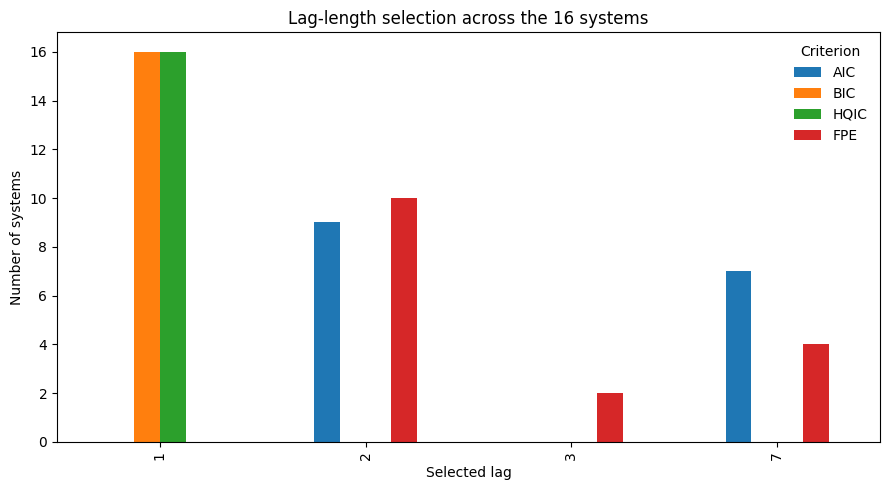

In [17]:
# ============================================================
# D1.2. SUMMARY OF SELECTED LAGS
# ============================================================

criteria = ["AIC", "BIC", "HQIC", "FPE"]

lag_counts = pd.DataFrame({
    criterion: lag_selection[criterion].value_counts().sort_index()
    for criterion in criteria
}).fillna(0).astype(int)

lag_counts.index.name = "Selected lag"

display(lag_counts)


fig, ax = plt.subplots(figsize=(9, 5))

lag_counts.plot(
    kind="bar",
    ax=ax,
)

ax.set_title("Lag-length selection across the 16 systems")
ax.set_xlabel("Selected lag")
ax.set_ylabel("Number of systems")
ax.legend(title="Criterion", frameon=False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "lag_selection_summary.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

### Lag-selection interpretation

The information criteria provide a diagnostic benchmark for the dynamic specification across the 16 country-origin systems.

The baseline BVAR uses a common lag length of **p = 2** across all systems. A common lag structure facilitates comparison of impulse responses across recipient economies and GPR origins while preserving a parsimonious quarterly specification.

## D2. Granger-causality diagnostics

Pairwise Granger-causality tests are used as a descriptive diagnostic of predictive relationships between geopolitical risk and the macro-financial variables.

For each of the 16 country-origin systems, the null hypothesis is that lagged values of the corresponding GPR index do not improve the prediction of the response variable conditional on its own lags.

These tests should not be interpreted as evidence of structural or economic causality.

In [18]:
# ============================================================
# D2. GRANGER-CAUSALITY TESTS
# ============================================================

from statsmodels.tsa.stattools import grangercausalitytests

GRANGER_LAGS = 2

granger_rows = []

for country in TARGET_COUNTRIES:

    country_data = (
        transformed_panel[
            transformed_panel[COUNTRY_COL] == country
        ]
        .sort_values("quarter")
        .copy()
    )

    for origin in GPR_ORIGINS:

        gpr_col = f"log1p_GPR_{origin.replace(' ', '_')}"

        for response in MACRO_COLS:

            test_data = (
                country_data[
                    [response, gpr_col]
                ]
                .dropna()
                .astype(float)
            )

            results = grangercausalitytests(
                test_data,
                maxlag=GRANGER_LAGS,
            )

            # SSR F-test at the baseline lag length p = 2
            f_stat = results[GRANGER_LAGS][0]["ssr_ftest"][0]
            p_value = results[GRANGER_LAGS][0]["ssr_ftest"][1]

            granger_rows.append({
                "country": country,
                "gpr_origin": origin,
                "response": response,
                "lags": GRANGER_LAGS,
                "F_statistic": f_stat,
                "p_value": p_value,
                "significant_5pct": p_value < 0.05,
            })


granger_results = pd.DataFrame(granger_rows)

display(granger_results)

,country,gpr_origin,response,lags,F_statistic,p_value,significant_5pct
0,Germany,Russia,dlog_Brent,2,1.387933,0.254006,False
1,Germany,Russia,dlog_Gas,2,1.704479,0.186722,False
2,Germany,Russia,dlog_HICP,2,1.216578,0.300269,False
3,Germany,Russia,dlog_IPI,2,1.229772,0.296420,False
4,Germany,Russia,CLIFS_level,2,0.914623,0.403748,False
...,...,...,...,...,...,...,...
75,Spain,Western Bloc,dlog_Brent,2,2.867123,0.061201,False
76,Spain,Western Bloc,dlog_Gas,2,0.001560,0.998441,False
77,Spain,Western Bloc,dlog_HICP,2,0.176895,0.838110,False
78,Spain,Western Bloc,dlog_IPI,2,2.499408,0.086875,False


In [19]:
# ============================================================
# D2.2. GRANGER-CAUSALITY SUMMARY
# ============================================================

granger_summary = (
    granger_results
    .groupby("gpr_origin")
    .agg(
        tests=("p_value", "size"),
        significant_5pct=("significant_5pct", "sum"),
    )
    .reset_index()
)

granger_summary["share_significant"] = (
    granger_summary["significant_5pct"]
    / granger_summary["tests"]
)

display(granger_summary)

,gpr_origin,tests,significant_5pct,share_significant
0,China,20,0,0.00
1,Middle East,20,1,0.05
2,Russia,20,0,0.00
3,Western Bloc,20,0,0.00


### Interpretation

The Granger-causality results are treated as a preliminary predictive diagnostic rather than as a structural identification strategy.

A rejection of the null indicates that lagged GPR contains predictive information for a given macro-financial variable within the specified system. It does **not** imply that geopolitical risk has been identified as an exogenous causal shock.

Structural interpretation in the subsequent BVAR analysis instead relies on the recursive identification scheme.

## E. Economic inspection of the transformed series

The following figures are not used to identify causal effects. Their purpose is to understand the scale, volatility and timing of the variables that will enter the BVAR.

Selected geopolitical and macro-financial episodes are shaded to provide historical context. Coincidence between an event and a movement in a series should therefore be interpreted descriptively, not causally.

In [20]:
# Broad event windows are used only as visual guides in the descriptive figures.
EVENTS = [
    ("9/11", "2001Q3", "2001Q4"),
    ("Iraq War", "2003Q1", "2003Q2"),
    ("Global Financial Crisis", "2008Q3", "2009Q2"),
    ("Euro-area debt crisis", "2010Q2", "2012Q3"),
    ("Crimea", "2014Q1", "2014Q2"),
    ("COVID-19", "2020Q1", "2020Q4"),
    ("Russia invades Ukraine", "2022Q1", "2022Q4"),
    ("Israel–Hamas war", "2023Q4", "2024Q1"),
]

def period_to_timestamp(q):
    return pd.Period(q, freq="Q").start_time

def shade_events(ax, add_labels=True):
    for label, start, end in EVENTS:
        x0 = period_to_timestamp(start)
        x1 = pd.Period(end, freq="Q").end_time
        ax.axvspan(x0, x1, alpha=0.10)

        if add_labels:
            midpoint = x0 + (x1 - x0) / 2
            ax.text(
                midpoint, 0.98, label,
                transform=ax.get_xaxis_transform(),
                rotation=90, va="top", ha="center",
                fontsize=8
            )

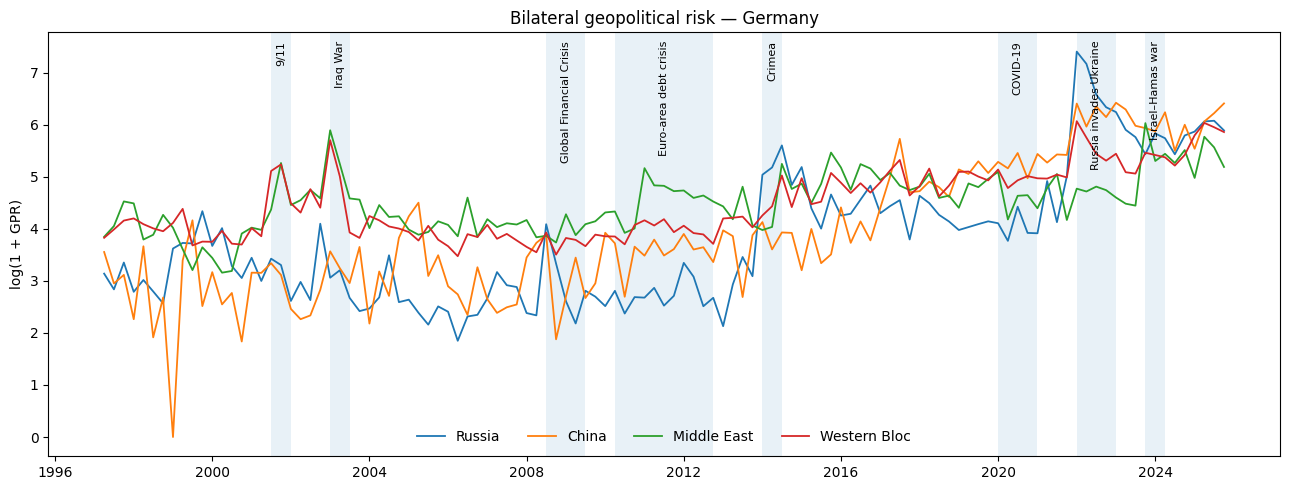

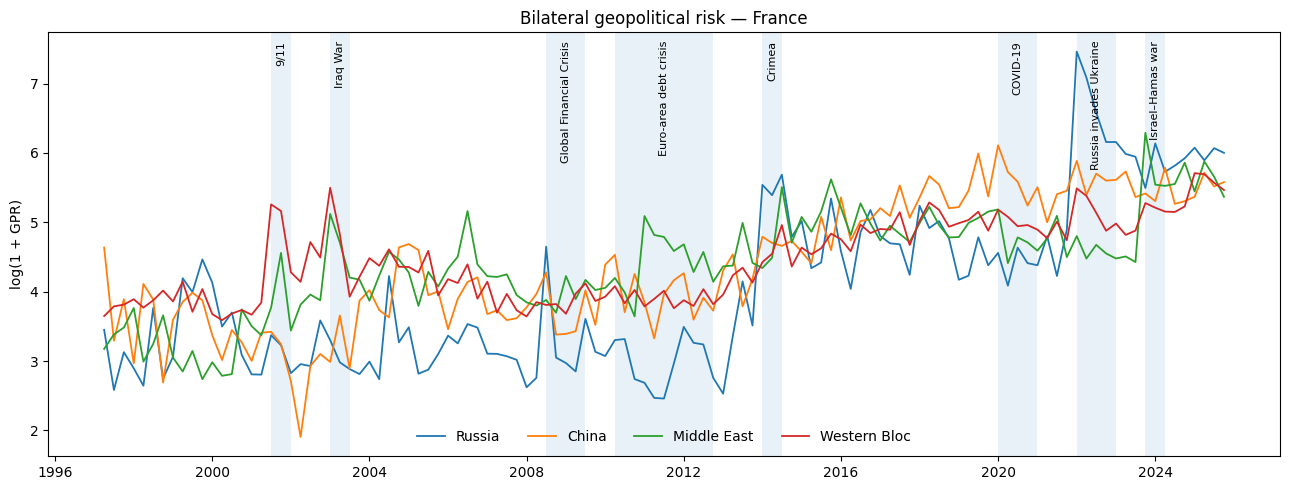

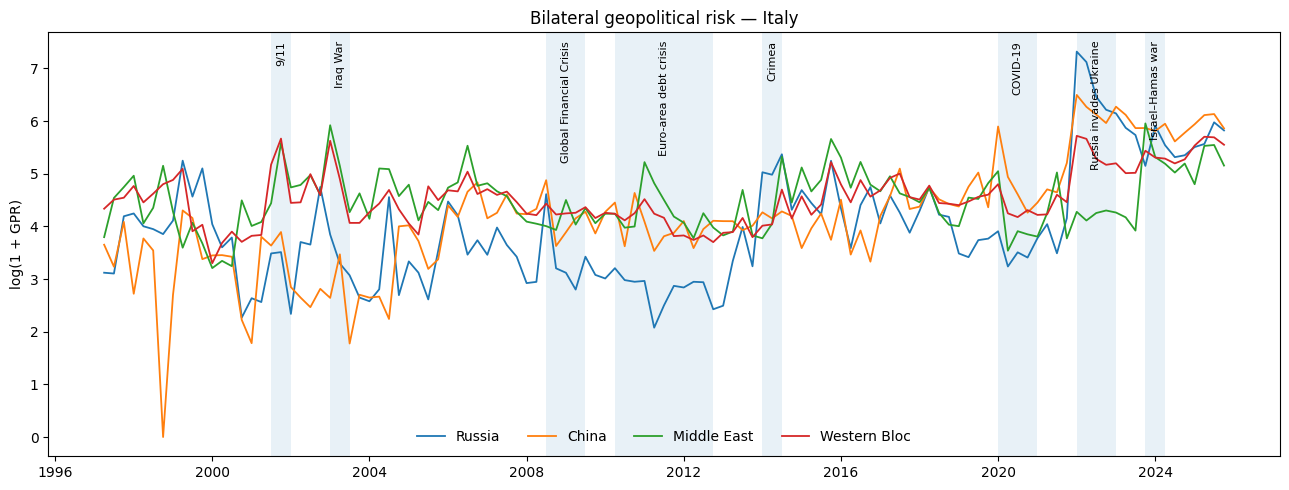

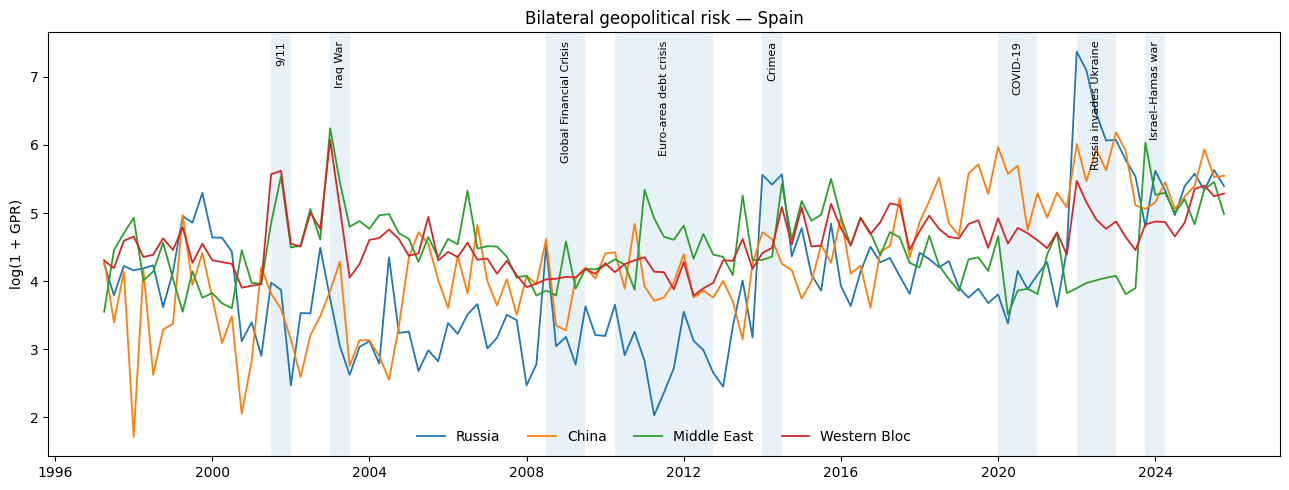

In [21]:
# GPR by geographical origin: one figure per recipient economy.
for country in TARGET_COUNTRIES:
    sub = (
        transformed_panel[transformed_panel[COUNTRY_COL] == country]
        .sort_values("quarter")
        .copy()
    )
    dates = sub["quarter"].dt.to_timestamp()

    fig, ax = plt.subplots(figsize=(13, 5))

    for origin in GPR_ORIGINS:
        col = f"log1p_GPR_{origin.replace(' ', '_')}"
        ax.plot(dates, sub[col], label=origin, linewidth=1.3)

    shade_events(ax)
    ax.set_title(f"Bilateral geopolitical risk — {country}")
    ax.set_ylabel("log(1 + GPR)")
    ax.set_xlabel("")
    ax.legend(ncol=4, frameon=False)
    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / f"01_gpr_{country.lower()}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

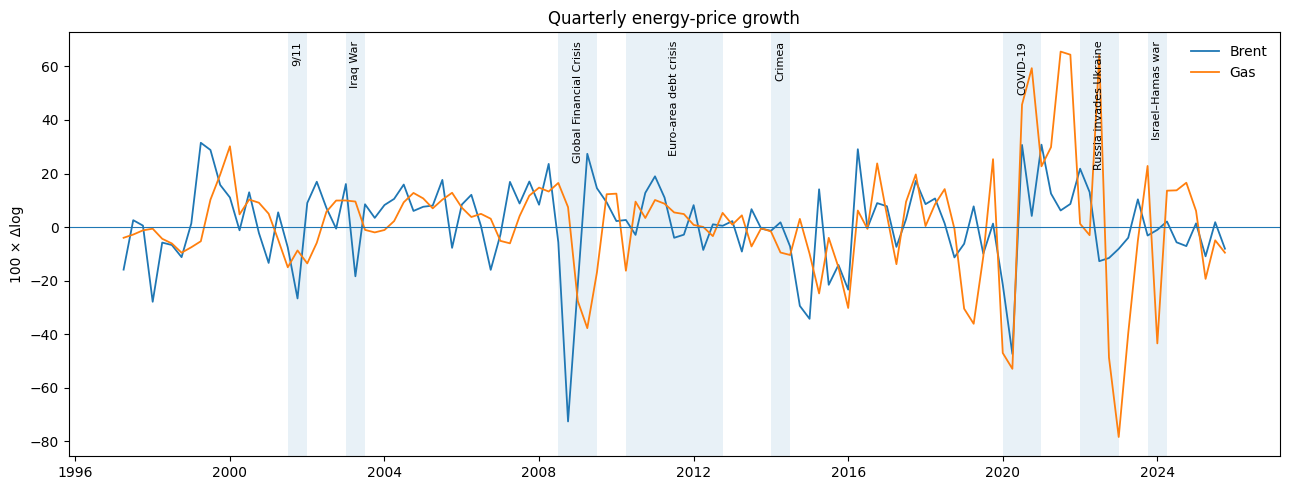

In [22]:
# Energy-price growth.
energy_plot = (
    transformed_panel[["quarter", "dlog_Brent", "dlog_Gas"]]
    .drop_duplicates("quarter")
    .sort_values("quarter")
    .copy()
)
dates = energy_plot["quarter"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(dates, 100 * energy_plot["dlog_Brent"], label="Brent", linewidth=1.3)
ax.plot(dates, 100 * energy_plot["dlog_Gas"], label="Gas", linewidth=1.3)

shade_events(ax)
ax.axhline(0, linewidth=0.8)
ax.set_title("Quarterly energy-price growth")
ax.set_ylabel("100 × Δlog")
ax.set_xlabel("")
ax.legend(frameon=False)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "02_energy_growth.png",
    dpi=160, bbox_inches="tight"
)
plt.show()
plt.close(fig)

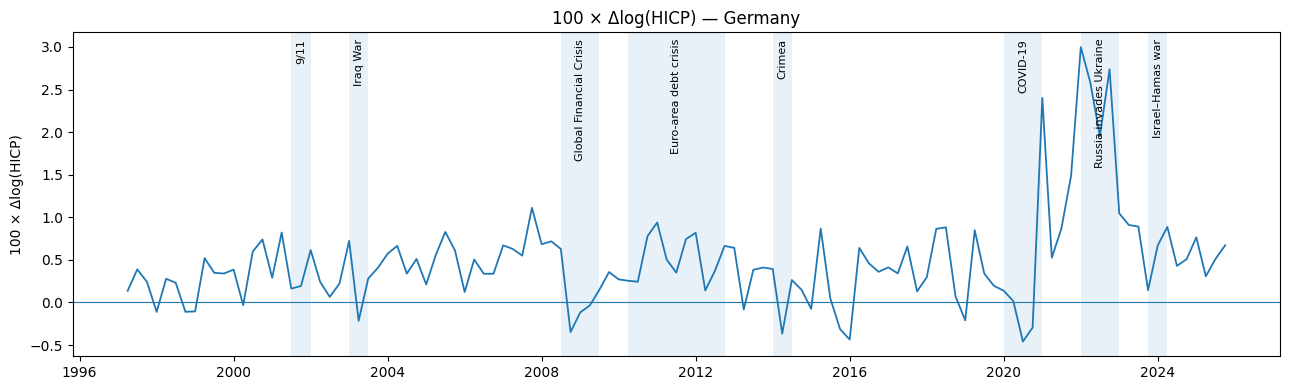

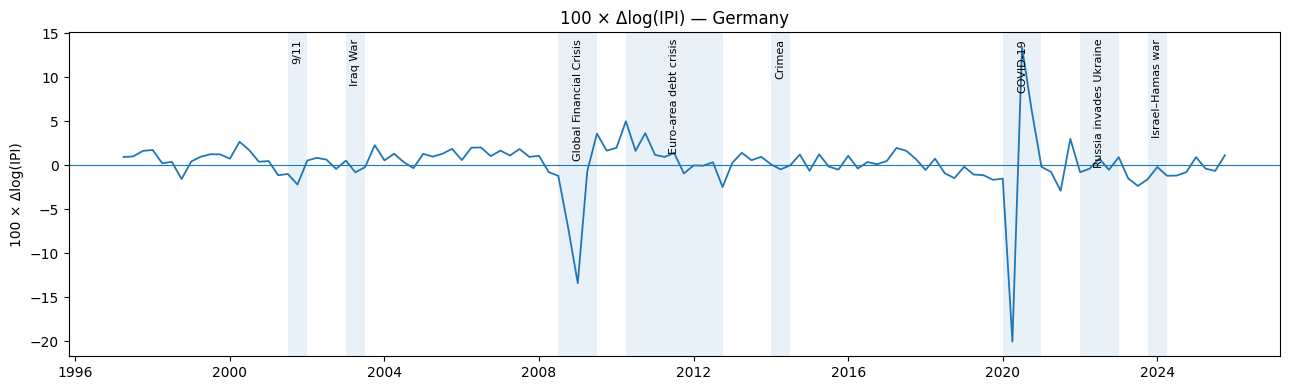

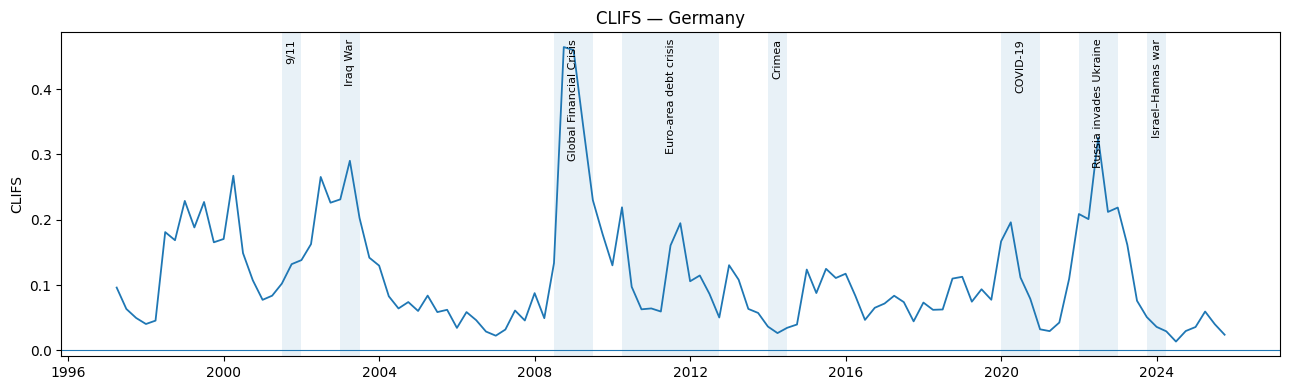

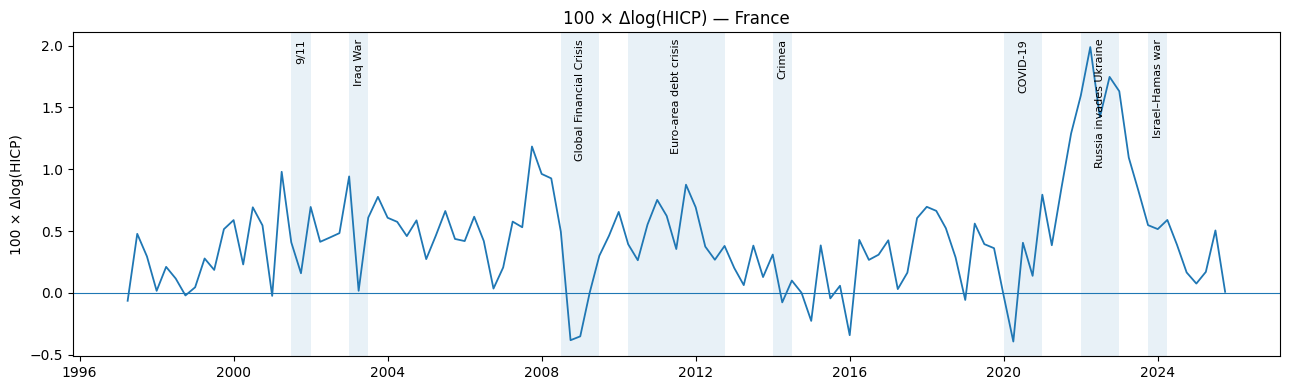

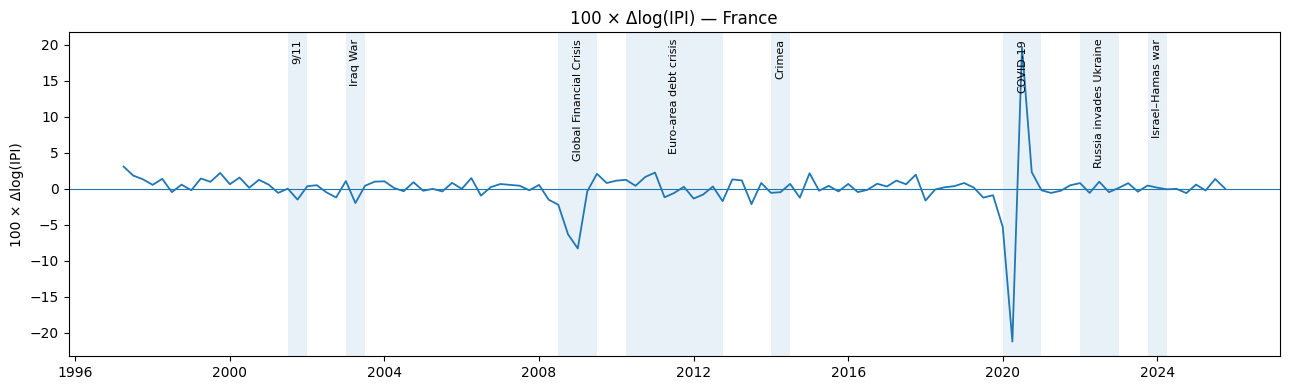

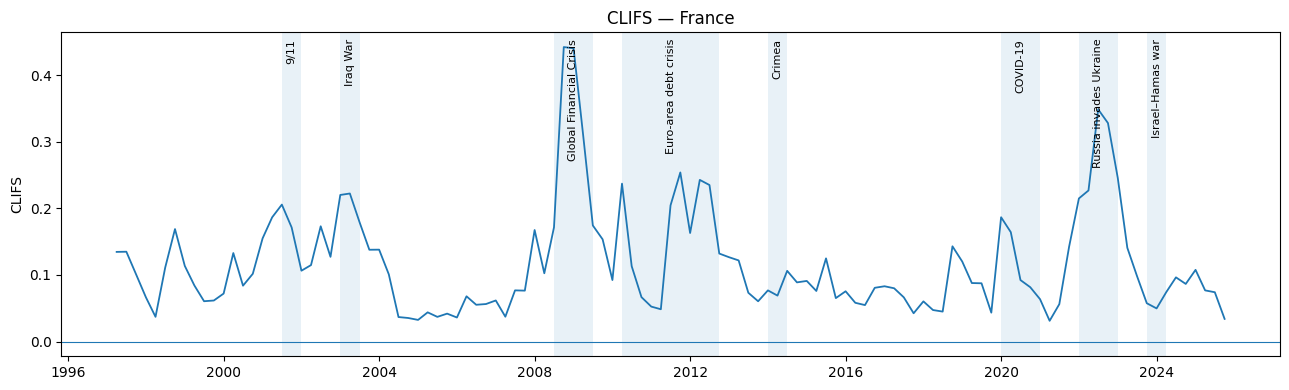

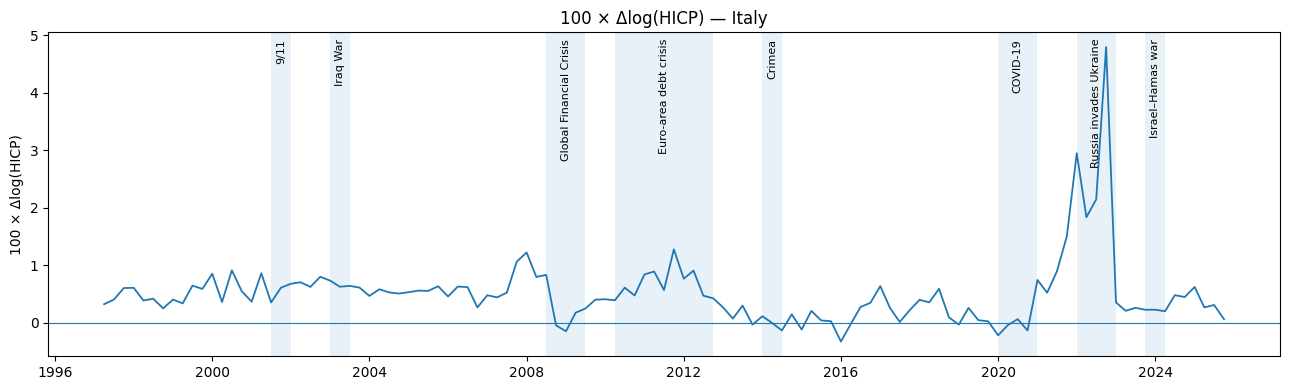

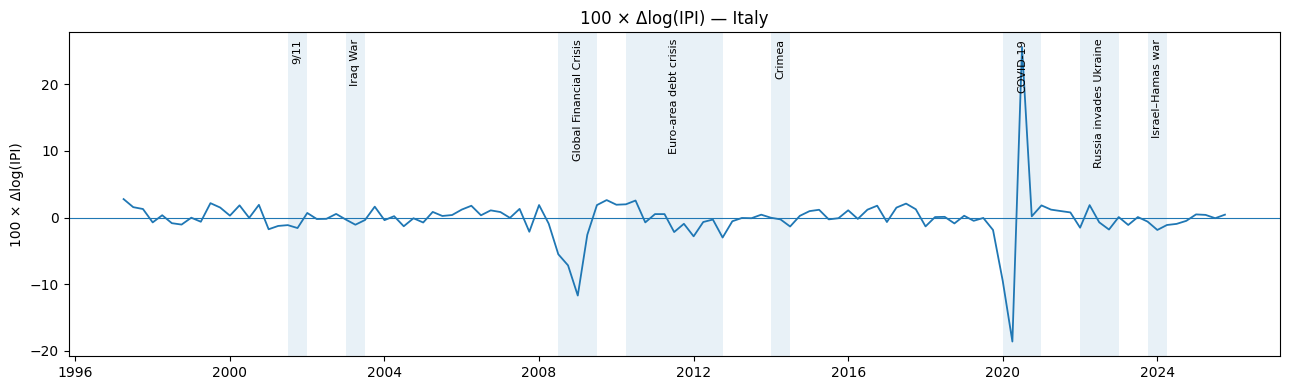

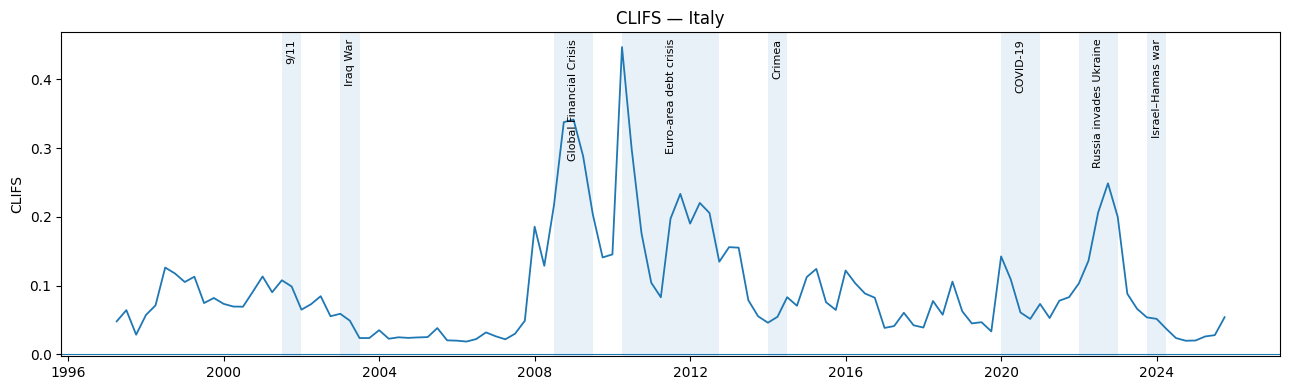

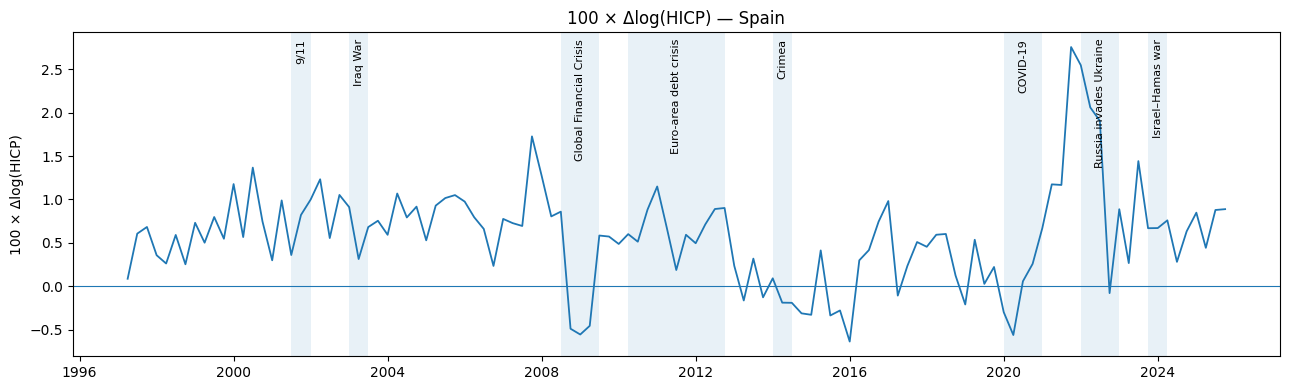

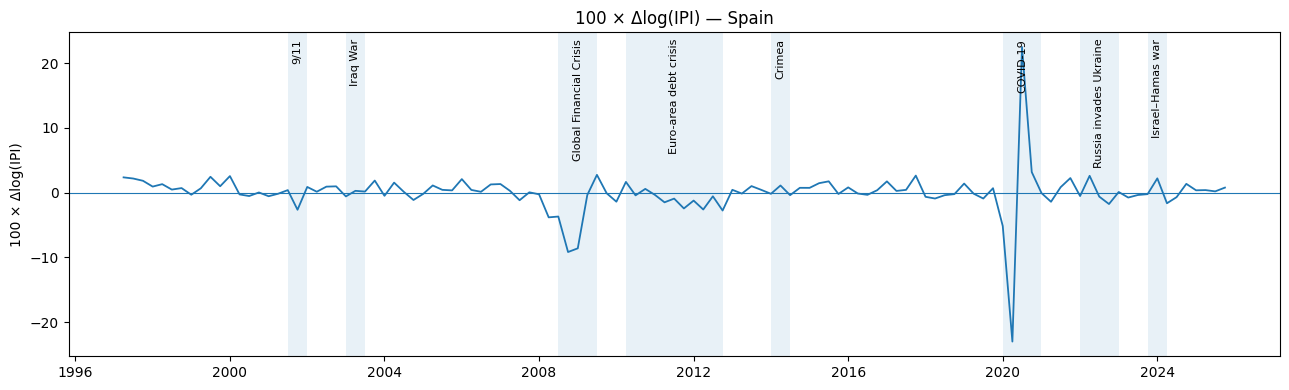

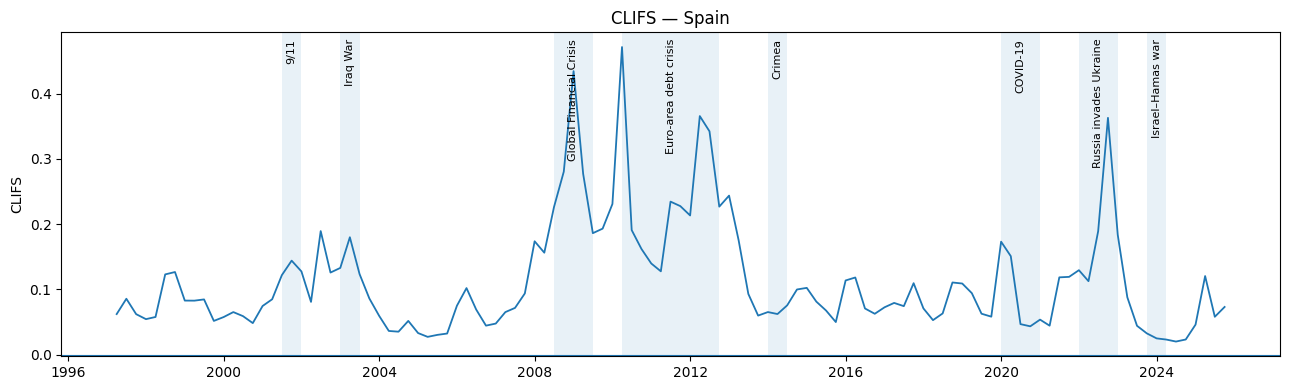

In [23]:
# Macro-financial variables: one compact figure per country.
for country in TARGET_COUNTRIES:
    sub = (
        transformed_panel[transformed_panel[COUNTRY_COL] == country]
        .sort_values("quarter")
        .copy()
    )
    dates = sub["quarter"].dt.to_timestamp()

    plot_specs = [
        ("dlog_HICP", "100 × Δlog(HICP)", 100),
        ("dlog_IPI", "100 × Δlog(IPI)", 100),
        ("CLIFS_level", "CLIFS", 1),
    ]

    for col, label, scale in plot_specs:
        fig, ax = plt.subplots(figsize=(13, 4))
        ax.plot(dates, scale * sub[col], linewidth=1.3)
        shade_events(ax)
        ax.axhline(0, linewidth=0.8)
        ax.set_title(f"{label} — {country}")
        ax.set_ylabel(label)
        ax.set_xlabel("")
        fig.tight_layout()

        safe_name = col.lower().replace("_level", "")
        fig.savefig(
            FIGURE_DIR / f"03_{safe_name}_{country.lower()}.png",
            dpi=160, bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

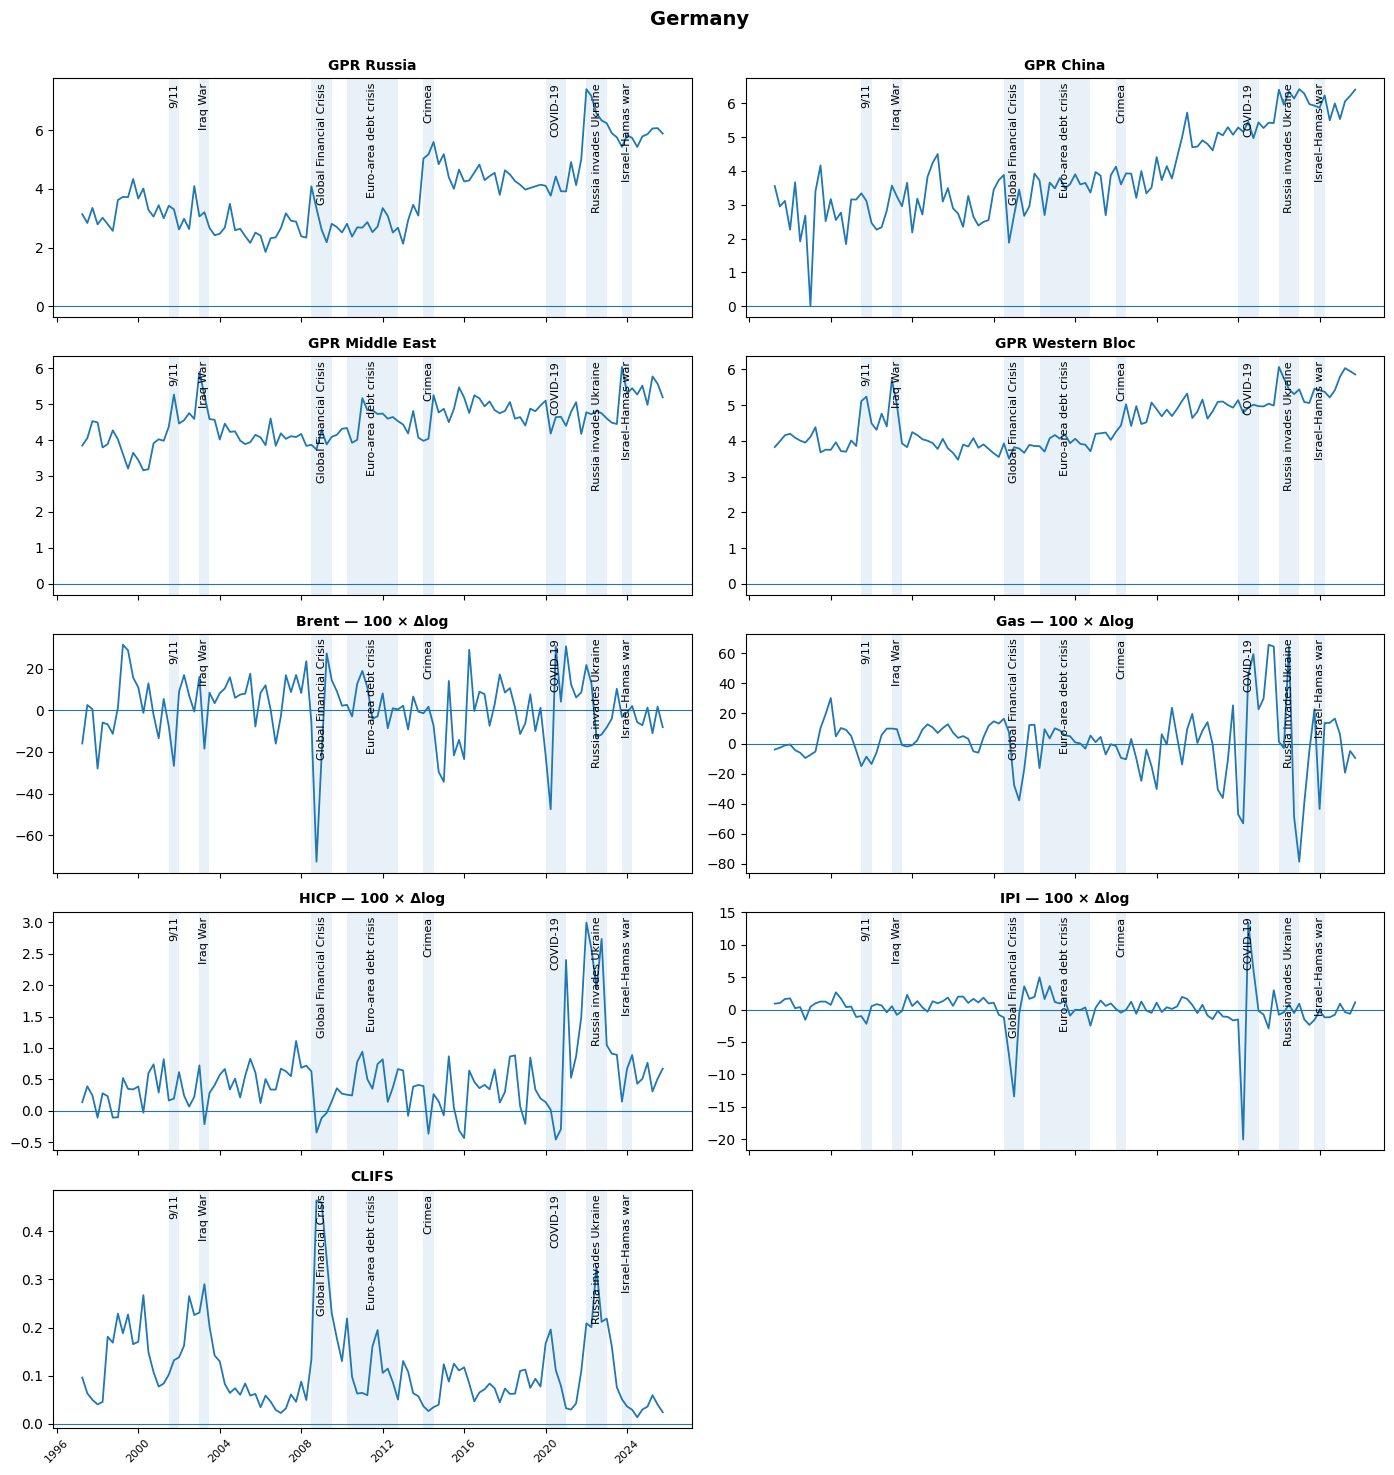

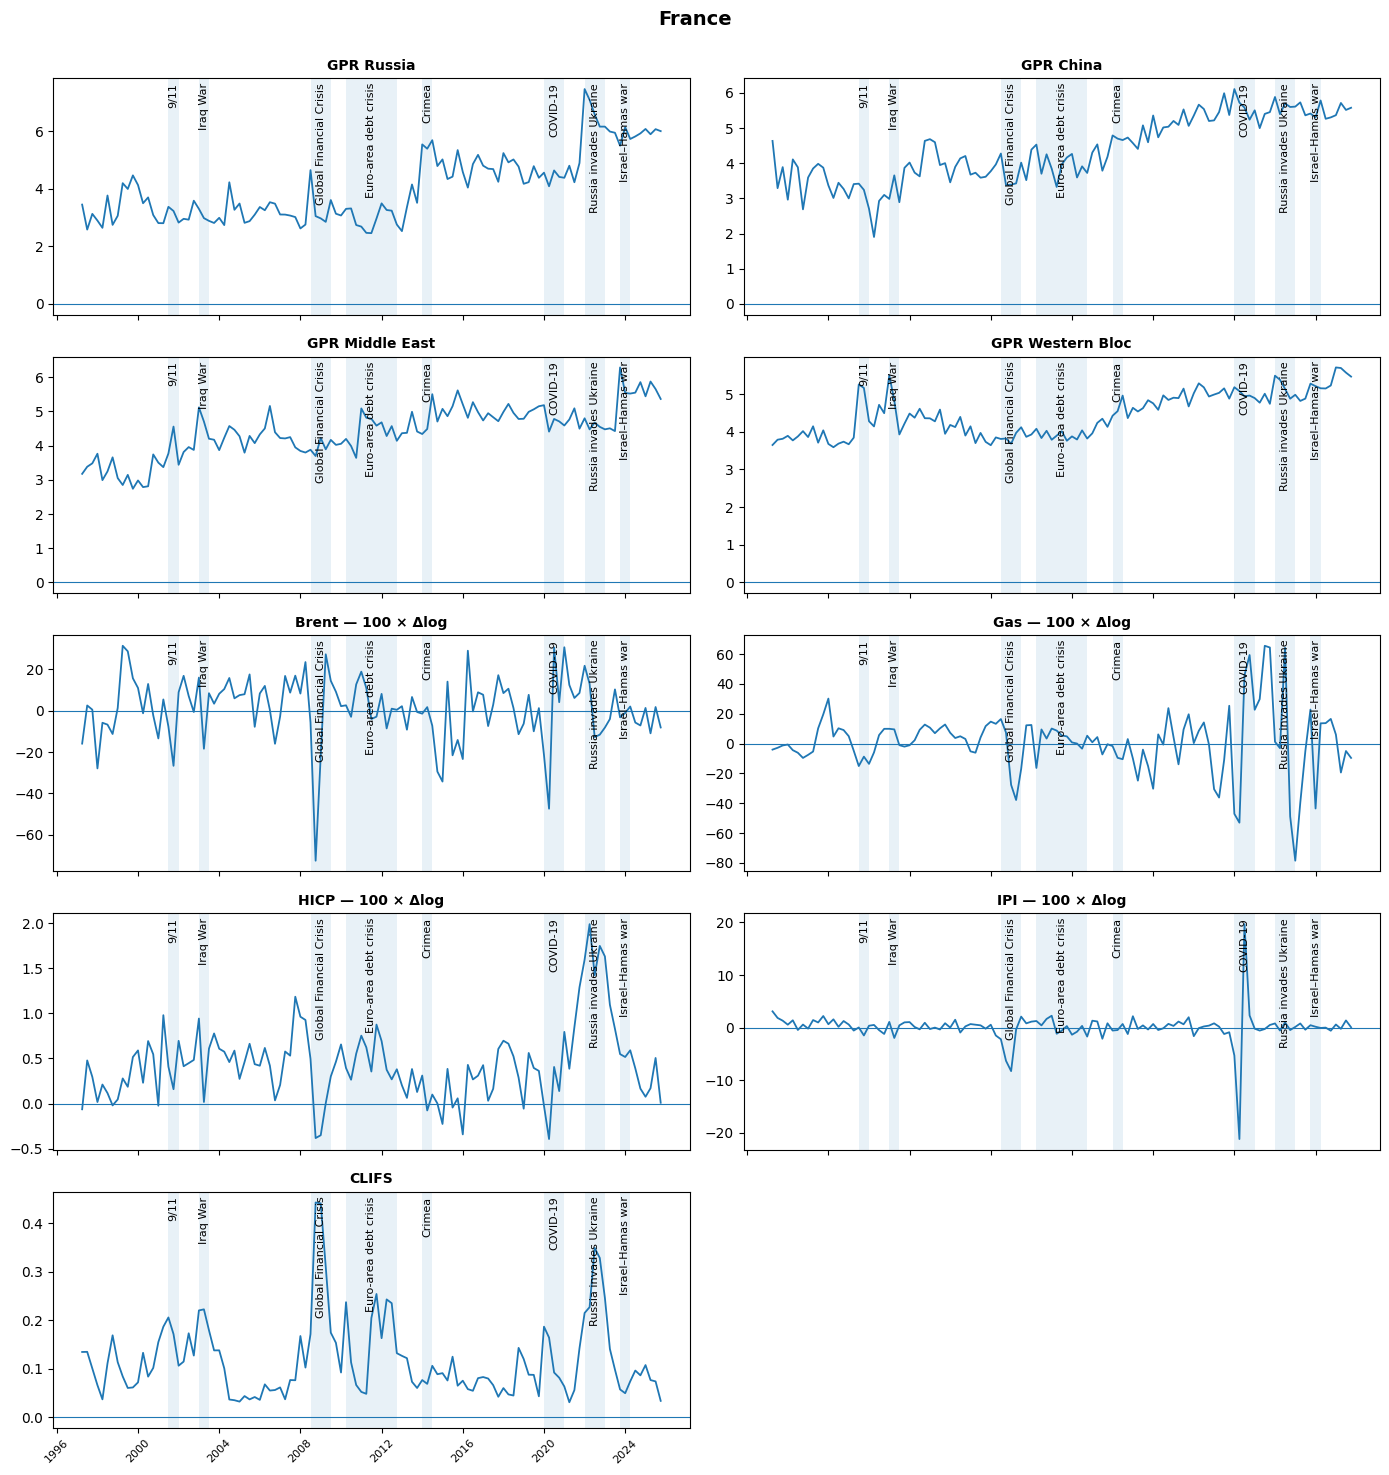

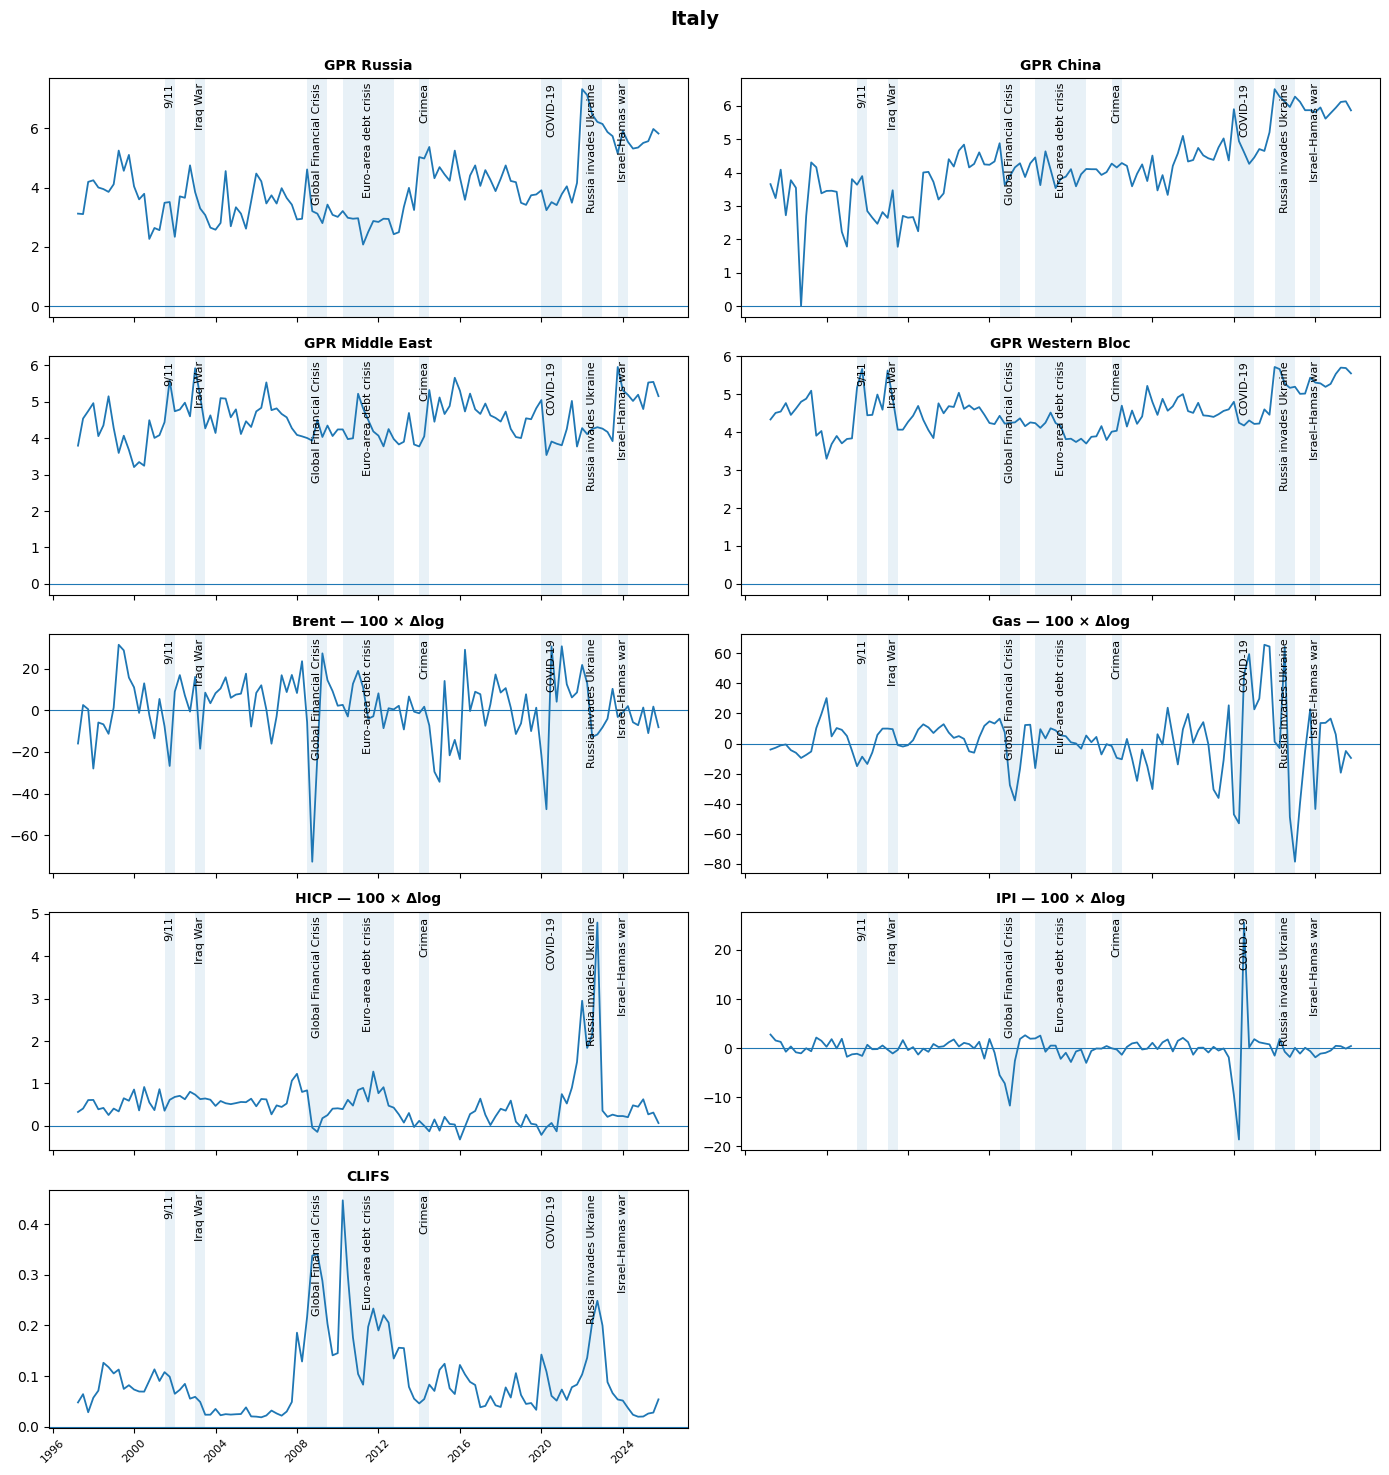

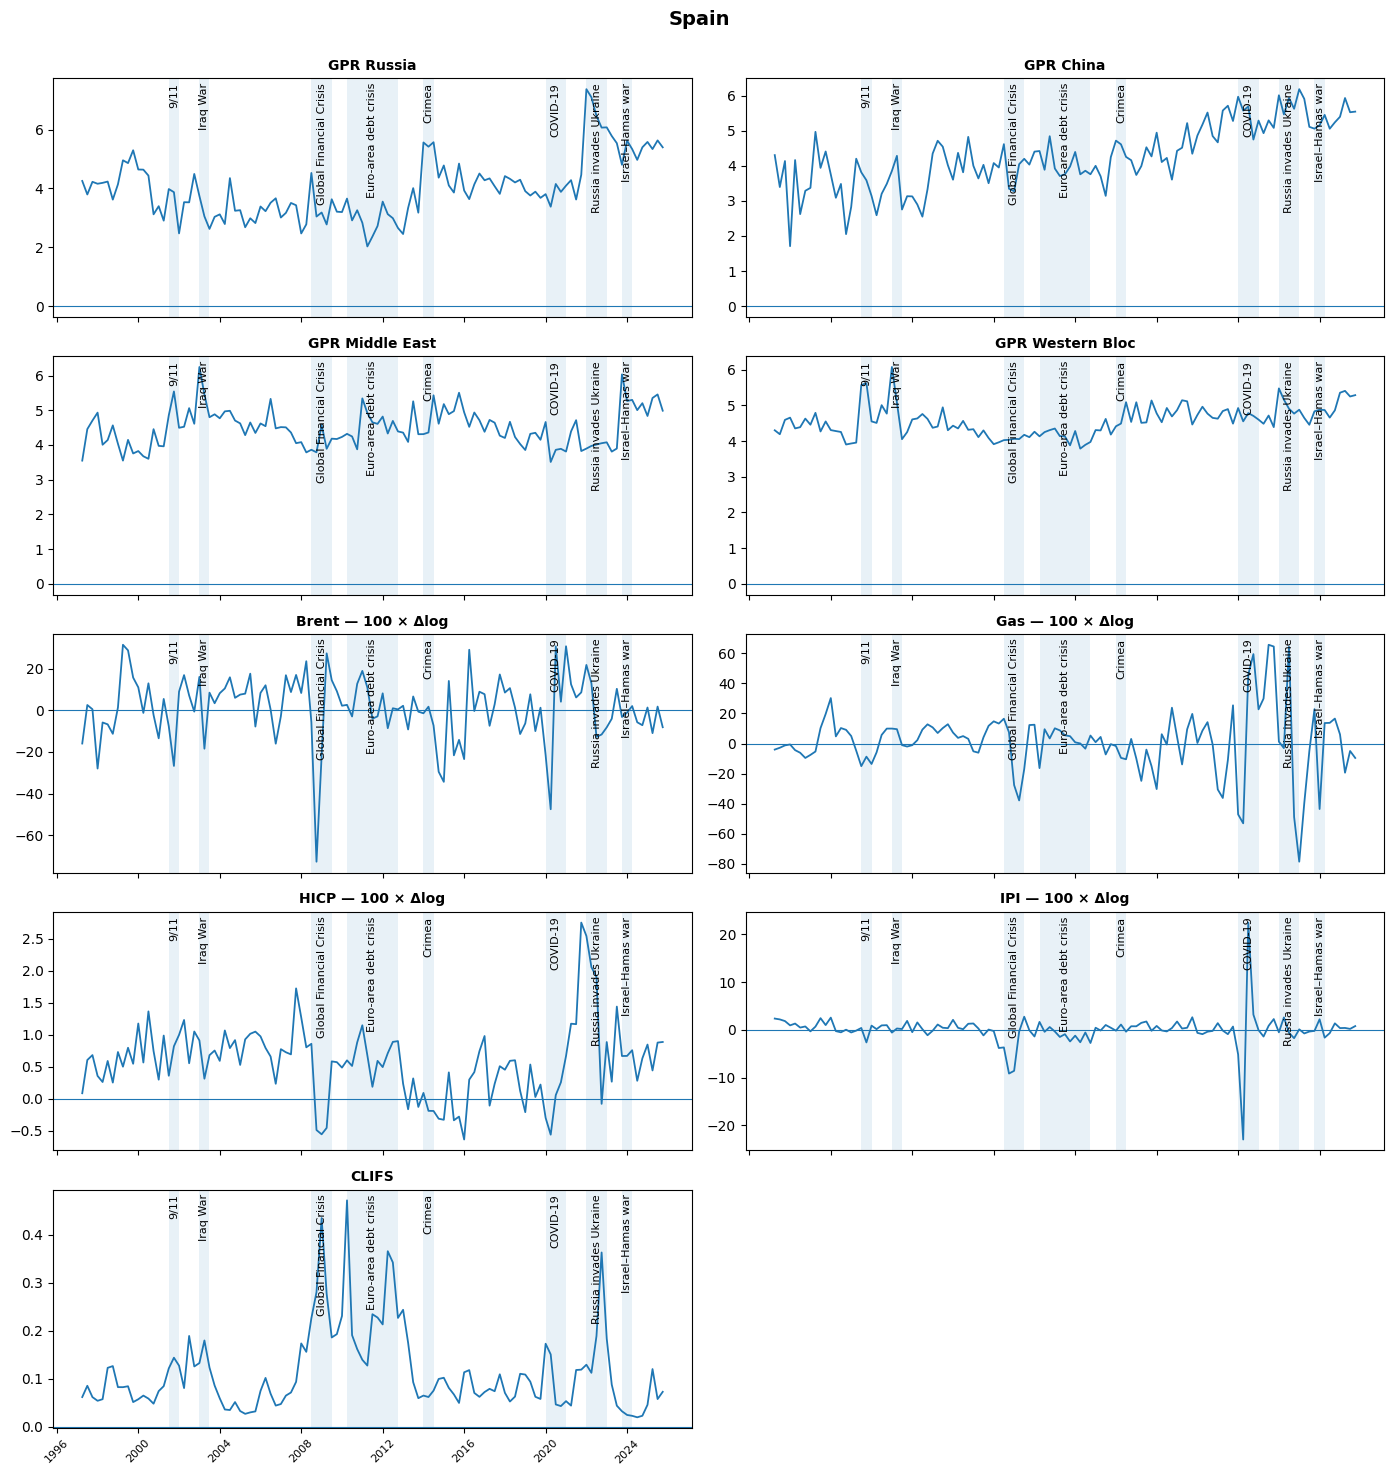

In [24]:
# ============================================================
# TRANSFORMED SERIES — ALL 9 SERIES PER COUNTRY
# ============================================================

# Four GPR origins + five macro-financial variables
GPR_PLOT_COLS = [
    f"log1p_GPR_{origin.replace(' ', '_')}"
    for origin in GPR_ORIGINS
]

PLOT_SPECS = (
    [(col, col.replace("log1p_GPR_", "GPR ").replace("_", " "), 1)
     for col in GPR_PLOT_COLS]
    + [
        ("dlog_Brent", "Brent — 100 × Δlog", 100),
        ("dlog_Gas", "Gas — 100 × Δlog", 100),
        ("dlog_HICP", "HICP — 100 × Δlog", 100),
        ("dlog_IPI", "IPI — 100 × Δlog", 100),
        ("CLIFS_level", "CLIFS", 1),
    ]
)


def plot_country_series(country):

    sub = (
        transformed_panel[
            transformed_panel[COUNTRY_COL] == country
        ]
        .sort_values("quarter")
        .copy()
    )

    dates = sub["quarter"].dt.to_timestamp()

    n_vars = len(PLOT_SPECS)
    n_cols = 2
    n_rows = int(np.ceil(n_vars / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 3 * n_rows),
        sharex=True,
    )

    axes = axes.flatten()

    for idx, (col, label, scale) in enumerate(PLOT_SPECS):

        ax = axes[idx]

        ax.plot(
            dates,
            scale * sub[col],
            linewidth=1.3,
        )

        # Uses the event periods already defined in NB03
        shade_events(ax)

        ax.axhline(
            0,
            linewidth=0.8,
        )

        ax.set_title(
            label,
            fontsize=10,
            fontweight="bold",
        )

        ax.set_xlabel("")
        ax.tick_params(
            axis="x",
            rotation=45,
            labelsize=8,
        )

    # Hide unused final subplot
    for idx in range(n_vars, len(axes)):
        axes[idx].set_visible(False)

    fig.suptitle(
        country,
        fontsize=14,
        fontweight="bold",
    )

    fig.tight_layout(rect=[0, 0, 1, 0.98])

    fig.savefig(
        FIGURE_DIR / f"04_all_series_{country.lower()}.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


for country in TARGET_COUNTRIES:
    plot_country_series(country)

### Descriptive statistics of the final BVAR variables

For readability, the log-differences are multiplied by 100 in the descriptive table. The BVAR itself continues to use the unscaled transformations.

In [25]:
desc_rows = []

# Common energy variables: report once.
energy_desc = transformed_panel[
    ["quarter", "dlog_Brent", "dlog_Gas"]
].drop_duplicates("quarter")

for variable in ["dlog_Brent", "dlog_Gas"]:
    x = 100 * energy_desc[variable].dropna()
    desc_rows.append({
        "country": "Common",
        "variable": variable,
        "mean": x.mean(),
        "std": x.std(),
        "min": x.min(),
        "max": x.max(),
    })

# Country-specific macro-financial variables.
for country in TARGET_COUNTRIES:
    sub = transformed_panel[transformed_panel[COUNTRY_COL] == country]

    for variable, scale in [
        ("dlog_HICP", 100),
        ("dlog_IPI", 100),
        ("CLIFS_level", 1),
    ]:
        x = scale * sub[variable].dropna()
        desc_rows.append({
            "country": country,
            "variable": variable,
            "mean": x.mean(),
            "std": x.std(),
            "min": x.min(),
            "max": x.max(),
        })

descriptive_macro = pd.DataFrame(desc_rows)
display(descriptive_macro.round(4))

descriptive_macro.to_csv(
    TABLE_DIR / "03_transformed_macro_descriptive_statistics.csv",
    index=False
)

,country,variable,mean,std,min,max
0,Common,dlog_Brent,0.9574,15.6142,-72.6752,31.4809
1,Common,dlog_Gas,1.1081,21.5351,-78.4979,65.5655
2,Germany,dlog_HICP,0.4799,0.5687,-0.4588,2.9985
3,Germany,dlog_IPI,0.1679,3.0375,-20.0378,13.4084
4,Germany,CLIFS_level,0.1141,0.0850,0.0135,0.4644
5,France,dlog_HICP,0.4350,0.4182,-0.3925,1.9877
6,France,dlog_IPI,0.0674,3.0943,-21.1938,19.6799
7,France,CLIFS_level,0.1177,0.0795,0.0312,0.4422
8,Italy,dlog_HICP,0.5092,0.6014,-0.3247,4.7953
9,Italy,dlog_IPI,-0.1509,3.5969,-18.6119,25.5731


In [26]:
gpr_desc_rows = []

for country in TARGET_COUNTRIES:
    sub = transformed_panel[transformed_panel[COUNTRY_COL] == country]

    for origin in GPR_ORIGINS:
        col = f"log1p_GPR_{origin.replace(' ', '_')}"
        x = sub[col].dropna()

        gpr_desc_rows.append({
            "country": country,
            "origin": origin,
            "mean": x.mean(),
            "std": x.std(),
            "min": x.min(),
            "max": x.max(),
        })

descriptive_gpr = pd.DataFrame(gpr_desc_rows)
display(descriptive_gpr.round(4))

descriptive_gpr.to_csv(
    TABLE_DIR / "04_transformed_gpr_descriptive_statistics.csv",
    index=False
)

,country,origin,mean,std,min,max
0,Germany,Russia,3.7785,1.2525,1.8491,7.4053
1,Germany,China,3.9310,1.2838,0.0000,6.4223
2,Germany,Middle East,4.4997,0.5660,3.1579,6.0313
3,Germany,Western Bloc,4.4756,0.6624,3.4741,6.0683
4,France,Russia,4.0332,1.1802,2.4593,7.4599
5,France,China,4.3809,0.9242,1.9050,6.1096
6,France,Middle East,4.4148,0.7330,2.7387,6.2897
7,France,Western Bloc,4.4558,0.5804,3.5887,5.7079
8,Italy,Russia,3.9631,1.0827,2.0765,7.3193
9,Italy,China,4.1610,1.0843,0.0000,6.4964


## F. Final BVAR-ready dataset

The final export contains exactly the variables required to construct the 16 baseline systems:

**4 recipient economies × 4 GPR origins = 16 BVARs**

Each individual system is ordered as:

`[log(1 + GPR_origin), Δlog(Brent), Δlog(Gas), Δlog(HICP), Δlog(IPI), CLIFS]`

The final checks below verify the common estimation window, balanced country coverage, missing values, duplicate observations and finite numerical values.

In [27]:
final_columns = (
    [COUNTRY_COL, "quarter"]
    + [f"log1p_GPR_{origin.replace(' ', '_')}" for origin in GPR_ORIGINS]
    + ["dlog_Brent", "dlog_Gas", "dlog_HICP", "dlog_IPI", "CLIFS_level"]
)

bvar_ready = (
    transformed_panel[final_columns]
    .rename(columns={COUNTRY_COL: "country"})
    .sort_values(["country", "quarter"])
    .reset_index(drop=True)
)

display(bvar_ready.head())

,country,quarter,log1p_GPR_Russia,log1p_GPR_China,log1p_GPR_Middle_East,log1p_GPR_Western_Bloc,dlog_Brent,dlog_Gas,dlog_HICP,dlog_IPI,CLIFS_level
0,France,1997Q2,3.449829,4.635563,3.175263,3.647935,-0.159255,-0.040290,-0.000630,0.030930,0.134633
1,France,1997Q3,2.582898,3.292862,3.383264,3.788105,0.025521,-0.028205,0.004780,0.018441,0.134900
2,France,1997Q4,3.128162,3.891049,3.482895,3.812795,0.005206,-0.012516,0.002956,0.013202,0.100700
3,France,1998Q1,2.895972,2.965333,3.763810,3.891038,-0.279539,-0.006317,0.000174,0.005558,0.066333
4,France,1998Q2,2.643882,4.110539,2.991503,3.770053,-0.058259,-0.044049,0.002111,0.013923,0.037133


In [28]:
expected_quarters = pd.period_range(
    ESTIMATION_START, SAMPLE_END, freq="Q"
)
expected_n = len(expected_quarters)

checks = {
    "sample starts in 1997Q2":
        bvar_ready["quarter"].min() == pd.Period(ESTIMATION_START, freq="Q"),
    "sample ends in 2025Q4":
        bvar_ready["quarter"].max() == pd.Period(SAMPLE_END, freq="Q"),
    "115 quarters per country":
        bvar_ready.groupby("country").size().eq(expected_n).all(),
    "four recipient economies":
        bvar_ready["country"].nunique() == 4,
    "no duplicate country-quarter observations":
        not bvar_ready.duplicated(["country", "quarter"]).any(),
    "no missing BVAR values":
        not bvar_ready.drop(columns=["country", "quarter"]).isna().any().any(),
    "all BVAR values finite":
        np.isfinite(
            bvar_ready.drop(columns=["country", "quarter"]).to_numpy(dtype=float)
        ).all(),
}

validation = pd.DataFrame({
    "check": list(checks.keys()),
    "passed": list(checks.values()),
})

display(validation)

if not validation["passed"].all():
    raise RuntimeError("At least one final BVAR-ready validation check failed.")

,check,passed
0,sample starts in 1997Q2,True
1,sample ends in 2025Q4,True
2,115 quarters per country,True
3,four recipient economies,True
4,no duplicate country-quarter observations,True
5,no missing BVAR values,True
6,all BVAR values finite,True


In [29]:
# Excel does not preserve pandas Period objects reliably, so quarters are
# exported in the transparent YYYYQ# format used throughout the project.
export_panel = bvar_ready.copy()
export_panel["quarter"] = export_panel["quarter"].astype(str)

BVAR_READY_PATH = PROCESSED_DIR / "03_bvar_ready_panel.xlsx"
export_panel.to_excel(BVAR_READY_PATH, index=False)

validation.to_csv(
    TABLE_DIR / "05_bvar_ready_validation.csv", index=False
)

print(f"Saved BVAR-ready panel to: {BVAR_READY_PATH}")
print(f"Rows: {len(export_panel)}")
print(f"Observations per country: {expected_n}")

Saved BVAR-ready panel to: /content/drive/MyDrive/TFM_GitHub/data/processed/03_bvar_ready_panel.xlsx
Rows: 460
Observations per country: 115


## Final specification carried forward

Notebook 03 leaves the data in the exact form required for estimation:

`[log(1 + GPR_origin), Δlog(Brent), Δlog(Gas), Δlog(HICP), Δlog(IPI), CLIFS]`

The stationarity analysis explains why the persistent energy and macroeconomic variables are expressed as log-differences, why CLIFS is retained in levels, and why bilateral GPR is treated separately in the presence of structural breaks.

The next notebook addresses the COVID-era volatility treatment before the baseline BVARs are estimated.